# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 100 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 100, 100)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(1000, 2, 100, 100)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(2000, 2, 100, 100)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 100, 100), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creamos función de costo

In [20]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 100,100))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 100,100))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 100)
    y2 = tf.linspace(y_range_neg, y_range_pos, 100)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 100,100))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 100,100))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 100)
    y22 = tf.linspace(y_range_neg, y_range_pos, 100)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

# Creación del modelo

In [21]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [22]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(2,100,100)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(100, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(100, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(50, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(25, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(7, activation= custom_activation)
])


In [24]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Flatten layer
model.add(Flatten(input_shape=(2, 100, 100)))

# First Dense Layer
model.add(Dense(118, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after first dense layer

# Second Dense Layer
model.add(Dense(54, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after second dense layer

# Third Dense Layer
model.add(Dense(112, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Output Dense Layer
model.add(Dense(7, activation=custom_activation))

# Display the model's architecture
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 20000)             0         
                                                                 
 dense_5 (Dense)             (None, 118)               2360118   
                                                                 
 batch_normalization_2 (Batc  (None, 118)              472       
 hNormalization)                                                 
                                                                 
 dense_6 (Dense)             (None, 54)                6426      
                                                                 
 batch_normalization_3 (Batc  (None, 54)               216       
 hNormalization)                                                 
                                                                 
 dense_7 (Dense)             (None, 112)              

In [25]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 20000)             0         
                                                                 
 dense_5 (Dense)             (None, 118)               2360118   
                                                                 
 batch_normalization_2 (Batc  (None, 118)              472       
 hNormalization)                                                 
                                                                 
 dense_6 (Dense)             (None, 54)                6426      
                                                                 
 batch_normalization_3 (Batc  (None, 54)               216       
 hNormalization)                                                 
                                                                 
 dense_7 (Dense)             (None, 112)              

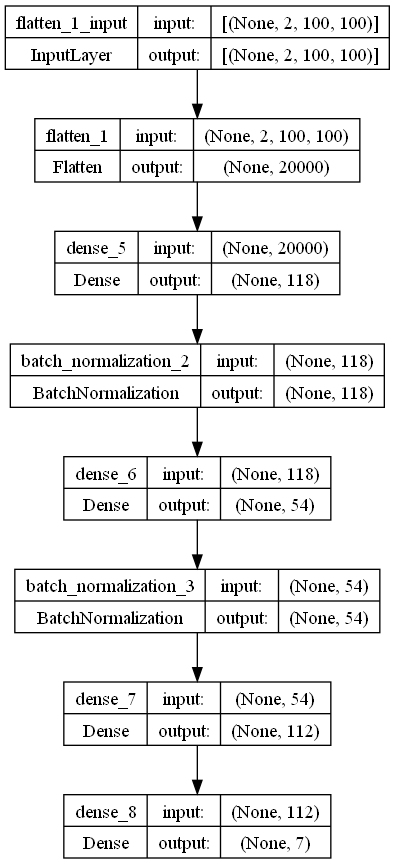

In [26]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [27]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [28]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [29]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [30]:
model.compile(optimizer=optimizer,
              loss= custom_loss,
              metrics=metrics)

In [31]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [33]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.0001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 10000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [34]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_mean_metric', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 4s 52ms/step - loss: 7.9520 - a_1: 2.5528 - a_2: 2.5649 - b_1: 2.6085 - b_2: 2.6223 - d_1: 0.4073 - d_2: 0.3781 - n: 1.5497 - mean_metric: 0.3957 - val_loss: 10.0233 - val_a_1: 2.5541 - val_a_2: 2.5394 - val_b_1: 2.5853 - val_b_2: 2.6521 - val_d_1: 0.4337 - val_d_2: 0.4746 - val_n: 1.5252 - val_mean_metric: 0.3980 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 4s 52ms/step - loss: 7.5286 - a_1: 2.5292 - a_2: 2.5695 - b_1: 2.5479 - b_2: 2.5850 - d_1: 0.3721 - d_2: 0.3747 - n: 1.5793 - mean_metric: 0.3918 - val_loss: 9.4041 - val_a_1: 2.5437 - val_a_2: 2.5419 - val_b_1: 2.4957 - val_b_2: 2.6030 - val_d_1: 0.3987 - val_d_2: 0.4428 - val_n: 1.5510 - val_mean_metric: 0.3921 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 4s 54ms/step - loss: 7.3091 - a_1: 2.5234 - a_2: 2.5648 - b_1: 2.4833 - b_2: 2.5415 - d_1: 0.3623 - d_2: 0.3589 - n: 1.5581 - mean_metric: 0.3867 - val_loss: 7.5993 - val_a_1: 2.519

70/70 [==============================] - 4s 53ms/step - loss: 5.4092 - a_1: 2.4770 - a_2: 2.4967 - b_1: 0.8037 - b_2: 0.8249 - d_1: 0.2307 - d_2: 0.2176 - n: 1.4681 - mean_metric: 0.2658 - val_loss: 4.6082 - val_a_1: 2.4770 - val_a_2: 2.4772 - val_b_1: 0.7344 - val_b_2: 0.8162 - val_d_1: 0.1614 - val_d_2: 0.1945 - val_n: 1.4660 - val_mean_metric: 0.2596 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 4s 52ms/step - loss: 5.2214 - a_1: 2.4791 - a_2: 2.4920 - b_1: 0.8150 - b_2: 0.8156 - d_1: 0.2087 - d_2: 0.2172 - n: 1.4672 - mean_metric: 0.2650 - val_loss: 3.8906 - val_a_1: 2.4788 - val_a_2: 2.4641 - val_b_1: 1.0971 - val_b_2: 1.0699 - val_d_1: 0.1815 - val_d_2: 0.1839 - val_n: 1.4919 - val_mean_metric: 0.2795 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 4s 53ms/step - loss: 5.0498 - a_1: 2.4789 - a_2: 2.4973 - b_1: 0.7745 - b_2: 0.8053 - d_1: 0.2247 - d_2: 0.1850 - n: 1.4754 - mean_metric: 0.2634 - val_loss: 5.7755 - val_a_1: 2.4763 - val_a_2:

70/70 [==============================] - 4s 53ms/step - loss: 4.5170 - a_1: 2.4663 - a_2: 2.4960 - b_1: 0.7779 - b_2: 0.6689 - d_1: 0.1781 - d_2: 0.1690 - n: 1.4297 - mean_metric: 0.2554 - val_loss: 4.4032 - val_a_1: 2.4830 - val_a_2: 2.4692 - val_b_1: 0.7655 - val_b_2: 0.8903 - val_d_1: 0.1513 - val_d_2: 0.1831 - val_n: 1.4182 - val_mean_metric: 0.2607 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 4s 53ms/step - loss: 4.4139 - a_1: 2.4659 - a_2: 2.5016 - b_1: 0.7419 - b_2: 0.7343 - d_1: 0.1739 - d_2: 0.1658 - n: 1.4310 - mean_metric: 0.2563 - val_loss: 3.0767 - val_a_1: 2.4841 - val_a_2: 2.4627 - val_b_1: 0.7287 - val_b_2: 0.5829 - val_d_1: 0.1101 - val_d_2: 0.1042 - val_n: 1.4294 - val_mean_metric: 0.2464 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 4s 53ms/step - loss: 4.7087 - a_1: 2.4656 - a_2: 2.4994 - b_1: 0.7137 - b_2: 0.7523 - d_1: 0.1833 - d_2: 0.1901 - n: 1.4263 - mean_metric: 0.2568 - val_loss: 6.6491 - val_a_1: 2.4895 - val_a_2:

70/70 [==============================] - 4s 52ms/step - loss: 4.0362 - a_1: 2.4691 - a_2: 2.4901 - b_1: 0.6563 - b_2: 0.6865 - d_1: 0.1479 - d_2: 0.1442 - n: 1.3916 - mean_metric: 0.2492 - val_loss: 4.3491 - val_a_1: 2.4746 - val_a_2: 2.4487 - val_b_1: 0.6786 - val_b_2: 0.7812 - val_d_1: 0.1767 - val_d_2: 0.2093 - val_n: 1.3726 - val_mean_metric: 0.2538 - lr: 9.9764e-04
Epoch 128/1000
70/70 [==============================] - 4s 52ms/step - loss: 4.2811 - a_1: 2.4696 - a_2: 2.4914 - b_1: 0.6695 - b_2: 0.6915 - d_1: 0.1687 - d_2: 0.1480 - n: 1.3943 - mean_metric: 0.2506 - val_loss: 3.2602 - val_a_1: 2.4785 - val_a_2: 2.4578 - val_b_1: 0.5857 - val_b_2: 0.5708 - val_d_1: 0.1148 - val_d_2: 0.1060 - val_n: 1.3898 - val_mean_metric: 0.2402 - lr: 9.9755e-04
Epoch 129/1000
70/70 [==============================] - 4s 52ms/step - loss: 4.2841 - a_1: 2.4705 - a_2: 2.4922 - b_1: 0.6846 - b_2: 0.6957 - d_1: 0.1774 - d_2: 0.1387 - n: 1.4010 - mean_metric: 0.2515 - val_loss: 6.2791 - val_a_1: 2.4752 

70/70 [==============================] - 4s 52ms/step - loss: 3.7545 - a_1: 2.4713 - a_2: 2.4872 - b_1: 0.5934 - b_2: 0.5842 - d_1: 0.1382 - d_2: 0.1253 - n: 1.3276 - mean_metric: 0.2411 - val_loss: 5.8226 - val_a_1: 2.4799 - val_a_2: 2.4568 - val_b_1: 0.5084 - val_b_2: 0.5232 - val_d_1: 0.1386 - val_d_2: 0.3536 - val_n: 1.3562 - val_mean_metric: 0.2437 - lr: 9.9382e-04
Epoch 170/1000
70/70 [==============================] - 4s 51ms/step - loss: 3.9647 - a_1: 2.4670 - a_2: 2.4864 - b_1: 0.6409 - b_2: 0.6023 - d_1: 0.1448 - d_2: 0.1332 - n: 1.3341 - mean_metric: 0.2437 - val_loss: 4.5804 - val_a_1: 2.4914 - val_a_2: 2.4720 - val_b_1: 0.6211 - val_b_2: 0.6438 - val_d_1: 0.1410 - val_d_2: 0.2216 - val_n: 1.3651 - val_mean_metric: 0.2480 - lr: 9.9373e-04
Epoch 171/1000
70/70 [==============================] - 4s 53ms/step - loss: 3.7691 - a_1: 2.4713 - a_2: 2.4880 - b_1: 0.6136 - b_2: 0.6145 - d_1: 0.1318 - d_2: 0.1288 - n: 1.3253 - mean_metric: 0.2425 - val_loss: 4.8470 - val_a_1: 2.4931 

70/70 [==============================] - 4s 52ms/step - loss: 3.3737 - a_1: 2.4674 - a_2: 2.4845 - b_1: 0.5393 - b_2: 0.5131 - d_1: 0.1210 - d_2: 0.1079 - n: 1.3023 - mean_metric: 0.2351 - val_loss: 4.3844 - val_a_1: 2.4844 - val_a_2: 2.4621 - val_b_1: 0.5932 - val_b_2: 0.5094 - val_d_1: 0.2728 - val_d_2: 0.0892 - val_n: 1.2978 - val_mean_metric: 0.2403 - lr: 9.9000e-04
Epoch 212/1000
70/70 [==============================] - 4s 51ms/step - loss: 3.4629 - a_1: 2.4722 - a_2: 2.4860 - b_1: 0.5208 - b_2: 0.5789 - d_1: 0.1214 - d_2: 0.1149 - n: 1.3037 - mean_metric: 0.2371 - val_loss: 4.9860 - val_a_1: 2.4782 - val_a_2: 2.4571 - val_b_1: 0.4632 - val_b_2: 0.5656 - val_d_1: 0.2902 - val_d_2: 0.1458 - val_n: 1.3022 - val_mean_metric: 0.2401 - lr: 9.8991e-04
Epoch 213/1000
70/70 [==============================] - 4s 51ms/step - loss: 3.5796 - a_1: 2.4637 - a_2: 2.4864 - b_1: 0.5255 - b_2: 0.5348 - d_1: 0.1261 - d_2: 0.1270 - n: 1.2983 - mean_metric: 0.2360 - val_loss: 3.8245 - val_a_1: 2.4751 

... (2 outputs left out)

70/70 [==============================] - 4s 53ms/step - loss: 2.9061 - a_1: 2.4641 - a_2: 2.4767 - b_1: 0.4770 - b_2: 0.4717 - d_1: 0.0954 - d_2: 0.0989 - n: 1.2482 - mean_metric: 0.2288 - val_loss: 3.6215 - val_a_1: 2.4689 - val_a_2: 2.4508 - val_b_1: 0.4354 - val_b_2: 0.6501 - val_d_1: 0.1654 - val_d_2: 0.0889 - val_n: 1.2869 - val_mean_metric: 0.2353 - lr: 9.7855e-04
Epoch 338/1000
70/70 [==============================] - 4s 53ms/step - loss: 2.9559 - a_1: 2.4661 - a_2: 2.4786 - b_1: 0.5418 - b_2: 0.5139 - d_1: 0.0938 - d_2: 0.1020 - n: 1.2502 - mean_metric: 0.2324 - val_loss: 3.0608 - val_a_1: 2.4625 - val_a_2: 2.4579 - val_b_1: 0.4504 - val_b_2: 0.4216 - val_d_1: 0.1568 - val_d_2: 0.0646 - val_n: 1.2665 - val_mean_metric: 0.2270 - lr: 9.7845e-04
Epoch 339/1000
70/70 [==============================] - 4s 52ms/step - loss: 3.0276 - a_1: 2.4605 - a_2: 2.4761 - b_1: 0.5165 - b_2: 0.4743 - d_1: 0.1064 - d_2: 0.0968 - n: 1.2394 - mean_metric: 0.2300 - val_loss: 6.5546 - val_a_1: 2.4727 

70/70 [==============================] - 4s 52ms/step - loss: 2.8681 - a_1: 2.4572 - a_2: 2.4783 - b_1: 0.5176 - b_2: 0.4873 - d_1: 0.0923 - d_2: 0.0904 - n: 1.2374 - mean_metric: 0.2297 - val_loss: 4.2652 - val_a_1: 2.4749 - val_a_2: 2.4687 - val_b_1: 0.5588 - val_b_2: 0.3490 - val_d_1: 0.1840 - val_d_2: 0.1325 - val_n: 1.2812 - val_mean_metric: 0.2322 - lr: 9.7473e-04
Epoch 380/1000
70/70 [==============================] - 4s 52ms/step - loss: 2.9538 - a_1: 2.4572 - a_2: 2.4766 - b_1: 0.4819 - b_2: 0.4937 - d_1: 0.0958 - d_2: 0.0996 - n: 1.2375 - mean_metric: 0.2291 - val_loss: 2.6548 - val_a_1: 2.4802 - val_a_2: 2.4711 - val_b_1: 0.7684 - val_b_2: 0.5464 - val_d_1: 0.0815 - val_d_2: 0.0547 - val_n: 1.3020 - val_mean_metric: 0.2402 - lr: 9.7464e-04
Epoch 381/1000
70/70 [==============================] - 4s 53ms/step - loss: 3.3121 - a_1: 2.4581 - a_2: 2.4782 - b_1: 0.4715 - b_2: 0.5384 - d_1: 0.1164 - d_2: 0.1141 - n: 1.2389 - mean_metric: 0.2314 - val_loss: 8.1806 - val_a_1: 2.5252 

70/70 [==============================] - 4s 53ms/step - loss: 2.9032 - a_1: 2.4539 - a_2: 2.4761 - b_1: 0.4805 - b_2: 0.4646 - d_1: 0.0968 - d_2: 0.0917 - n: 1.2444 - mean_metric: 0.2280 - val_loss: 3.3308 - val_a_1: 2.4632 - val_a_2: 2.4751 - val_b_1: 0.4577 - val_b_2: 0.4168 - val_d_1: 0.1367 - val_d_2: 0.1185 - val_n: 1.2686 - val_mean_metric: 0.2287 - lr: 9.7091e-04
Epoch 422/1000
70/70 [==============================] - 4s 53ms/step - loss: 2.8943 - a_1: 2.4591 - a_2: 2.4734 - b_1: 0.4816 - b_2: 0.4243 - d_1: 0.0925 - d_2: 0.0970 - n: 1.2506 - mean_metric: 0.2271 - val_loss: 4.8061 - val_a_1: 2.4762 - val_a_2: 2.4865 - val_b_1: 0.4400 - val_b_2: 0.5541 - val_d_1: 0.1716 - val_d_2: 0.2558 - val_n: 1.2824 - val_mean_metric: 0.2390 - lr: 9.7082e-04
Epoch 423/1000
70/70 [==============================] - 4s 53ms/step - loss: 2.8176 - a_1: 2.4626 - a_2: 2.4754 - b_1: 0.4496 - b_2: 0.4471 - d_1: 0.0859 - d_2: 0.0977 - n: 1.2472 - mean_metric: 0.2266 - val_loss: 6.7845 - val_a_1: 2.4684 

70/70 [==============================] - 4s 53ms/step - loss: 2.6760 - a_1: 2.4543 - a_2: 2.4708 - b_1: 0.4727 - b_2: 0.4307 - d_1: 0.0834 - d_2: 0.0863 - n: 1.2423 - mean_metric: 0.2259 - val_loss: 3.9912 - val_a_1: 2.4752 - val_a_2: 2.4622 - val_b_1: 0.6507 - val_b_2: 0.7829 - val_d_1: 0.1007 - val_d_2: 0.1729 - val_n: 1.3053 - val_mean_metric: 0.2479 - lr: 9.6709e-04
Epoch 464/1000
70/70 [==============================] - 4s 53ms/step - loss: 2.7191 - a_1: 2.4541 - a_2: 2.4741 - b_1: 0.4682 - b_2: 0.4837 - d_1: 0.0905 - d_2: 0.0851 - n: 1.2376 - mean_metric: 0.2275 - val_loss: 8.6173 - val_a_1: 2.5552 - val_a_2: 2.6455 - val_b_1: 0.7454 - val_b_2: 0.3917 - val_d_1: 0.4687 - val_d_2: 0.2372 - val_n: 1.4201 - val_mean_metric: 0.2639 - lr: 9.6700e-04
Epoch 465/1000
70/70 [==============================] - 4s 53ms/step - loss: 2.6873 - a_1: 2.4558 - a_2: 2.4726 - b_1: 0.4715 - b_2: 0.4481 - d_1: 0.0927 - d_2: 0.0825 - n: 1.2370 - mean_metric: 0.2265 - val_loss: 8.5927 - val_a_1: 2.4650 

# Analizamos accuracy y loss

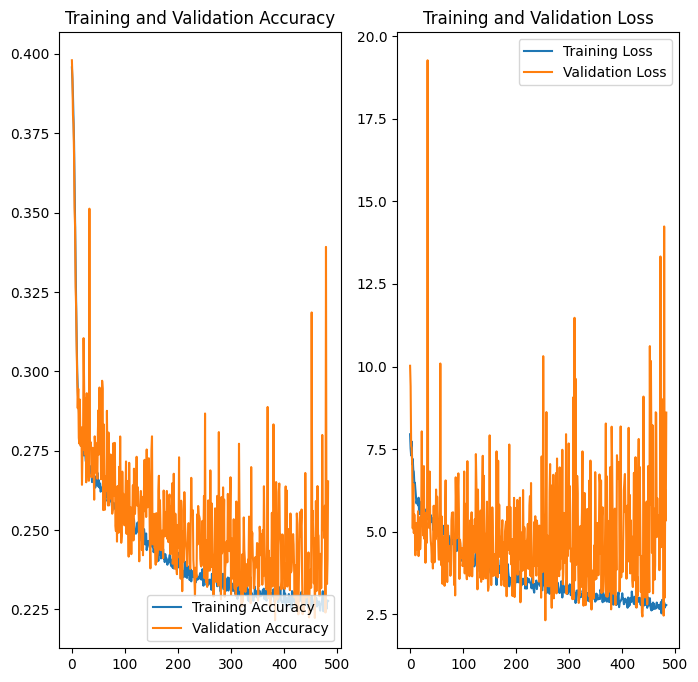

In [36]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(484)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

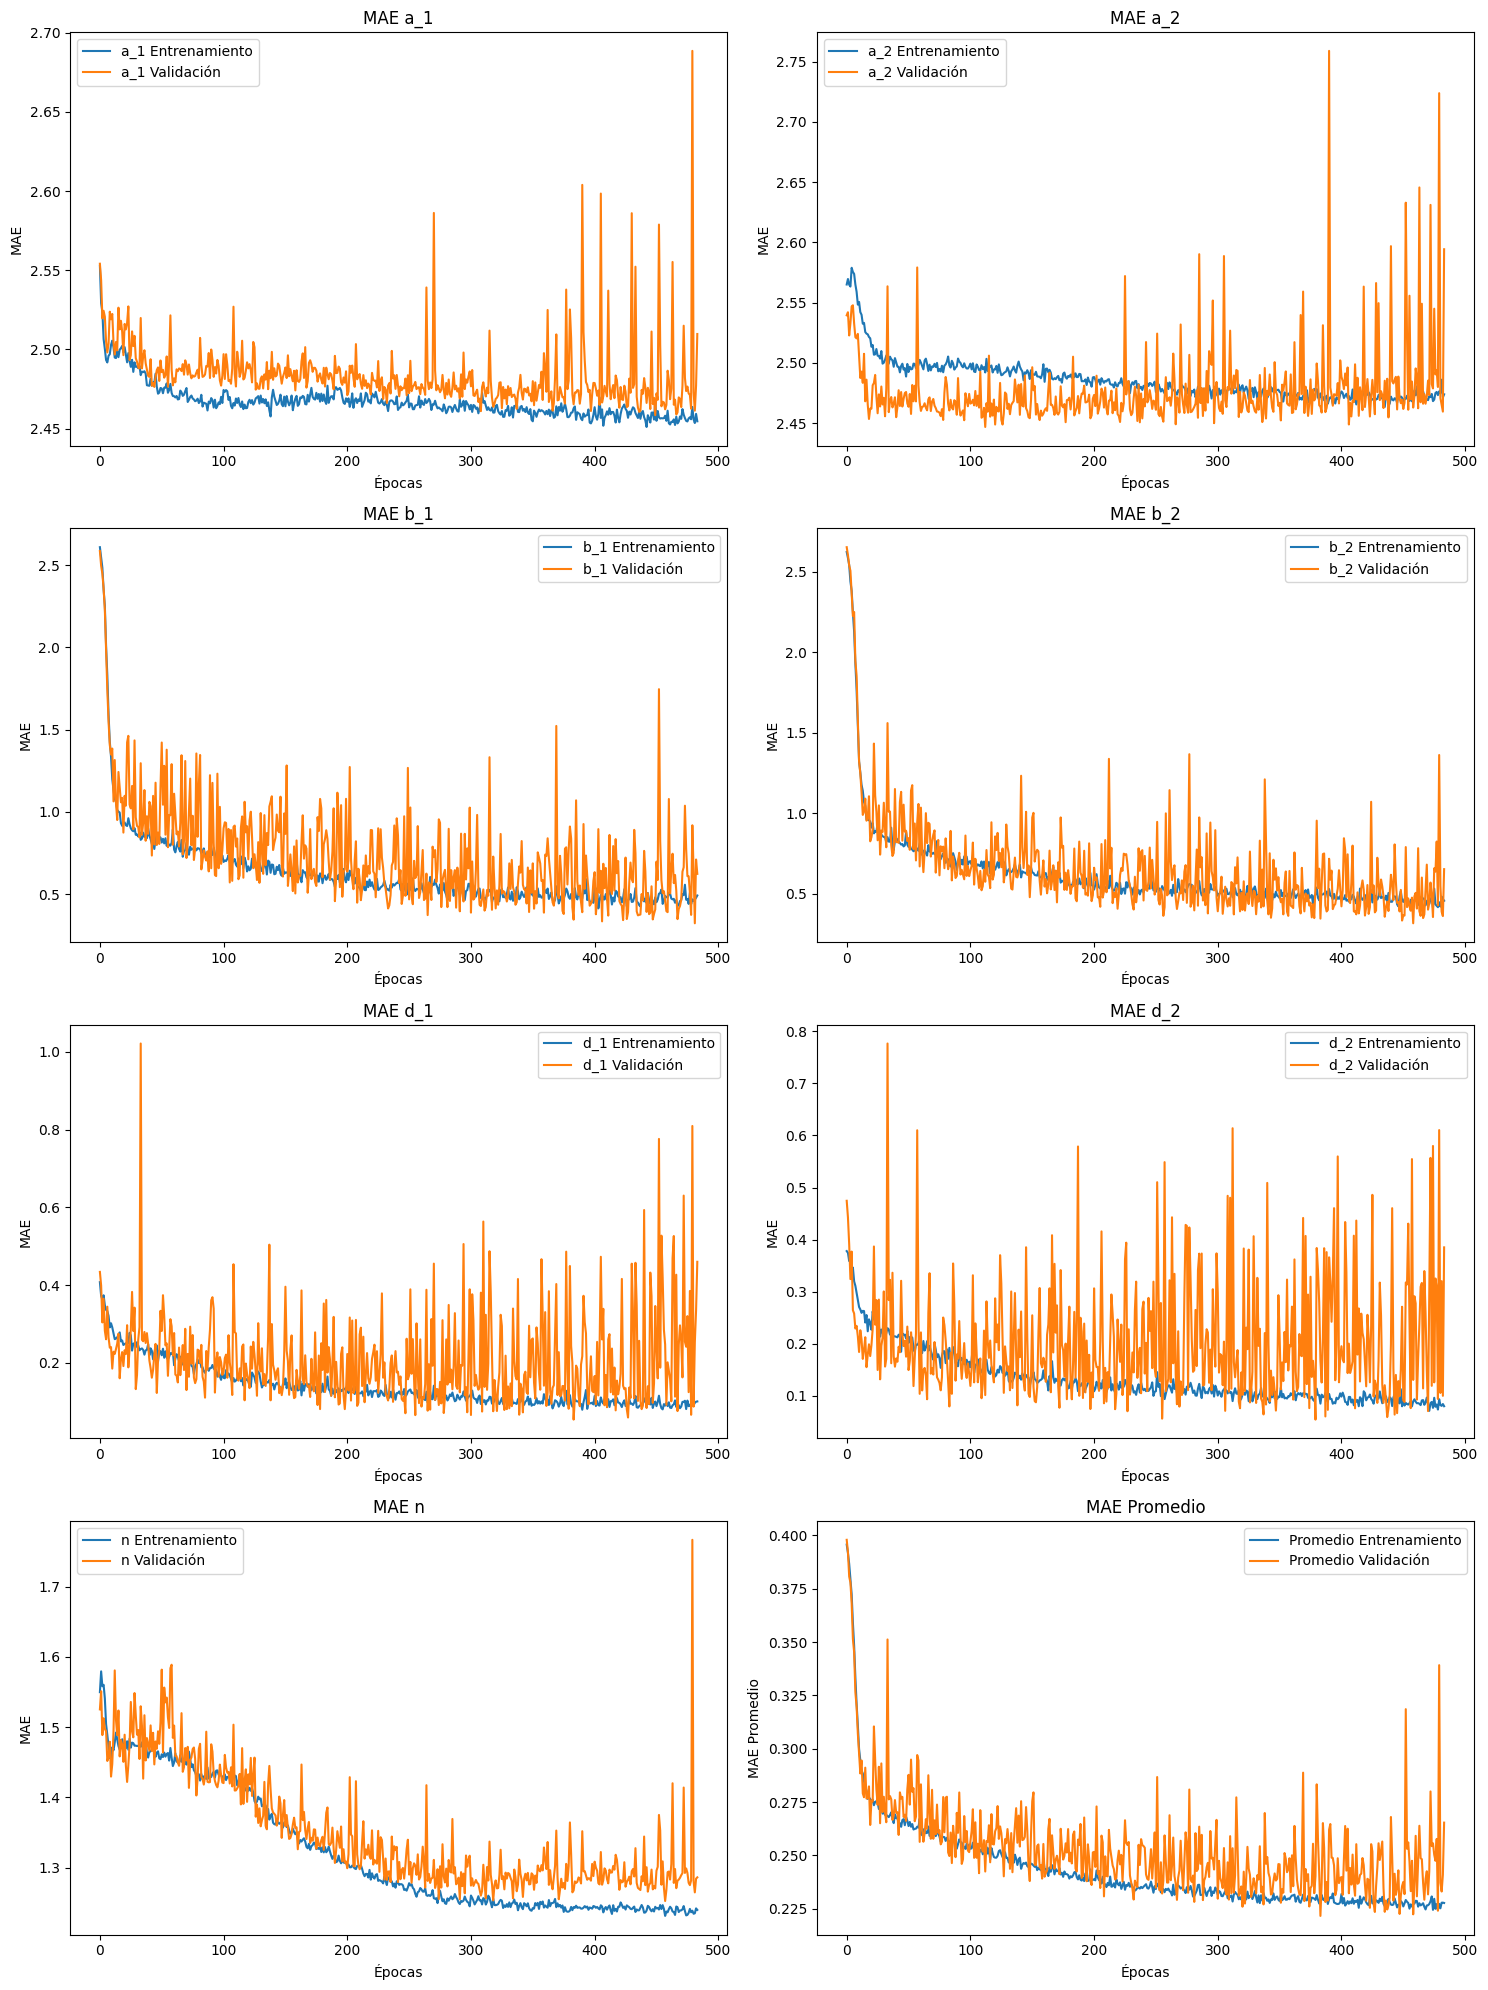

In [37]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [38]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 6ms/step - loss: 3.1086 - a_1: 2.4716 - a_2: 2.3910 - b_1: 0.3475 - b_2: 0.3229 - d_1: 0.0502 - d_2: 0.1687 - n: 1.2107 - mean_metric: 0.2171


In [39]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 2ms/step


In [40]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[1 2 9 6 0 2 5]
[5.9069815e+00 5.0234365e+00 8.4935865e+00 5.6631141e+00 5.1561557e-04
 1.9446410e+00 2.5056579e+00]
[25 52 33 47 31 39 39 43 30 28 43 39 46 26 39 34 27 33 30 42 36 35 36 32
 42 30 29 33 31 30 17 38 36 24 38 17 33 50 31 44 13 48 38 22 46 28 25 48
 32 29 36 49 31 38 32 32 32 30 42 40 34 41 33 26 39 24 42 29 33 33 22 27
 30 18 33 36 40 27 22 20 47 30 47 32 39 38 41 27 31 35 28 43 46 49 48 45
 31 25 39 41 31 45 43 25 33 39 18 37 14 29 34 41 27 36 34 34 32 35 45 22
 45 40 48 41 35 36 42 38 20 46 35 29 25 25 54 25 39 24 41 25 31 23 37 35
 35 37 26 39 36 35 28 40 39 29 40 31 32 10 43 49 36 35 36 42 34 18 47 44
 23 43 30 30 22 39 35 34 28 37 21 41 31 31 32 40 33 44 32 31 19 41 35 49
 33 22 35 33 40 30 32 32 36 30 42 23 30 27 32 25 38 44 35 33 24 42 28 34
 26 32 29 30 40 34 33 32 45 27 19 33 31 48 26 41 46 42 30 35 38 40 39 43
 30 42 41 31 29 40 30 47 36 31 37 41 34 38 28 44 37 43 44 34 26 39 28 33
 27 18 34 37 26 46 35 40 43 46 30 39 43 13 32 40 33 41 28 20 43 41 35 32
 22 34 

1.6177048733724015

In [41]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.9970233763496867, Desviación estándar del error: 1.625116086984116, Error absoluto máximo: 5.836857318878174


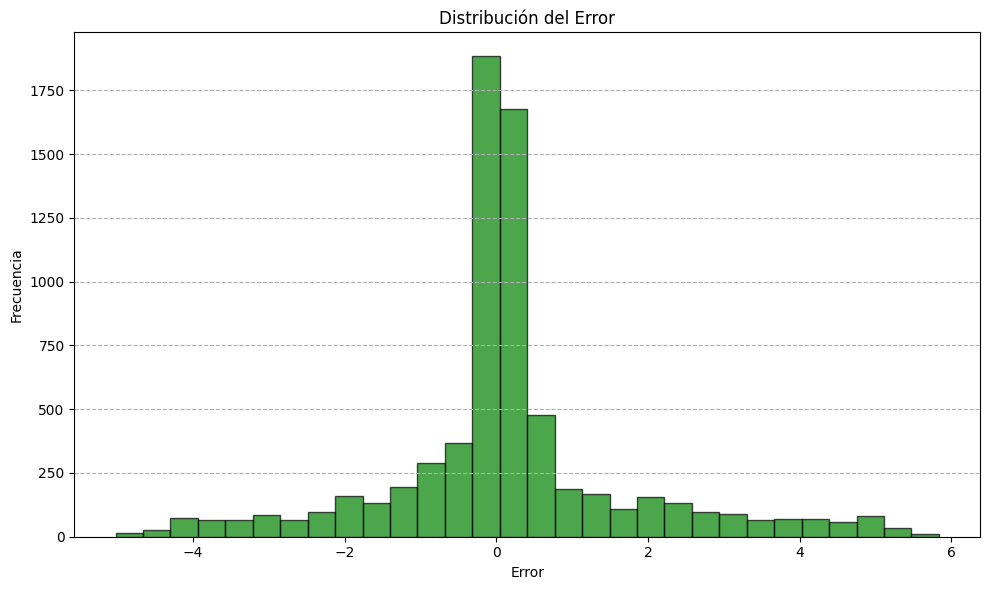

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [43]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.21594879723354474
Desviación estándar del error relativo: 0.13403339812531348
Error absoluto máximo relativo: 0.7723353922367096


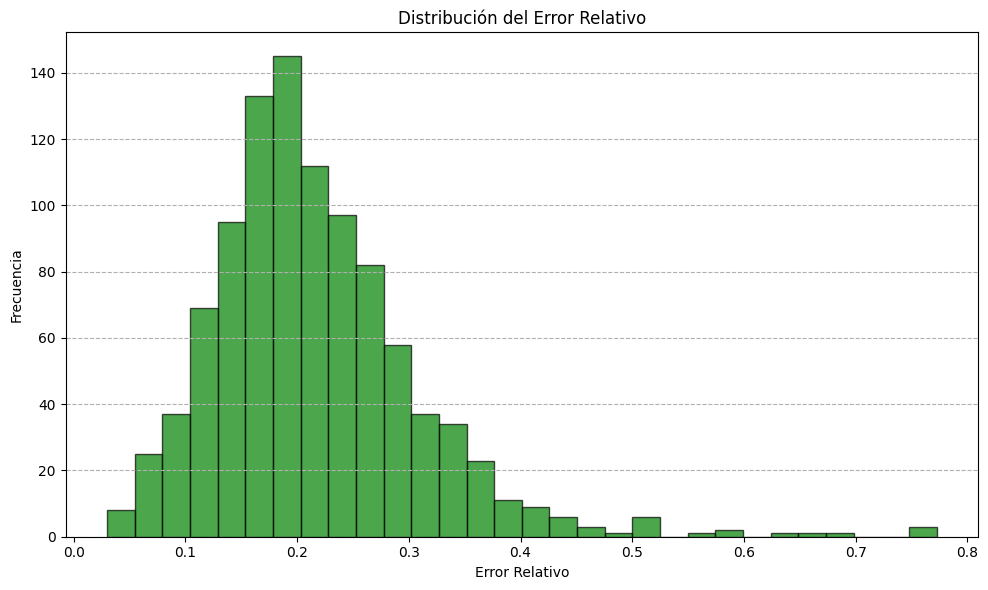

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()


# Guardamos los datos de Accuracy y Loss

In [45]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid100_traj200/historycampvec100funcioncosto.csv', index = False)

# Guardamos el modelo

In [46]:
path_to_save = '../../../trained_models_clean/grid100_traj200'

In [47]:
model.save(path_to_save + '/campovectorial100funcioncosto.h5')

# Importamos el modelo

In [48]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [49]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 100,100))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 100,100))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 100)
    y2 = tf.linspace(y_range_neg, y_range_pos, 100)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 100,100))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 100,100))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 100)
    y22 = tf.linspace(y_range_neg, y_range_pos, 100)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

In [50]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [51]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_loss':custom_loss,'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_clean/grid100_traj200/campovectorial100funcioncosto.h5', 
                                    custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [52]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b1

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[8, 9, 8, 9, 9, 5, 0]


In [55]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [56]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(np.shape(new_predictions))

1/1 [==============================] - 0s 13ms/step
(1, 7)


##  Encontramos puntos de equilibro datos reales

In [57]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(1.3333333333333333, 2.5)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

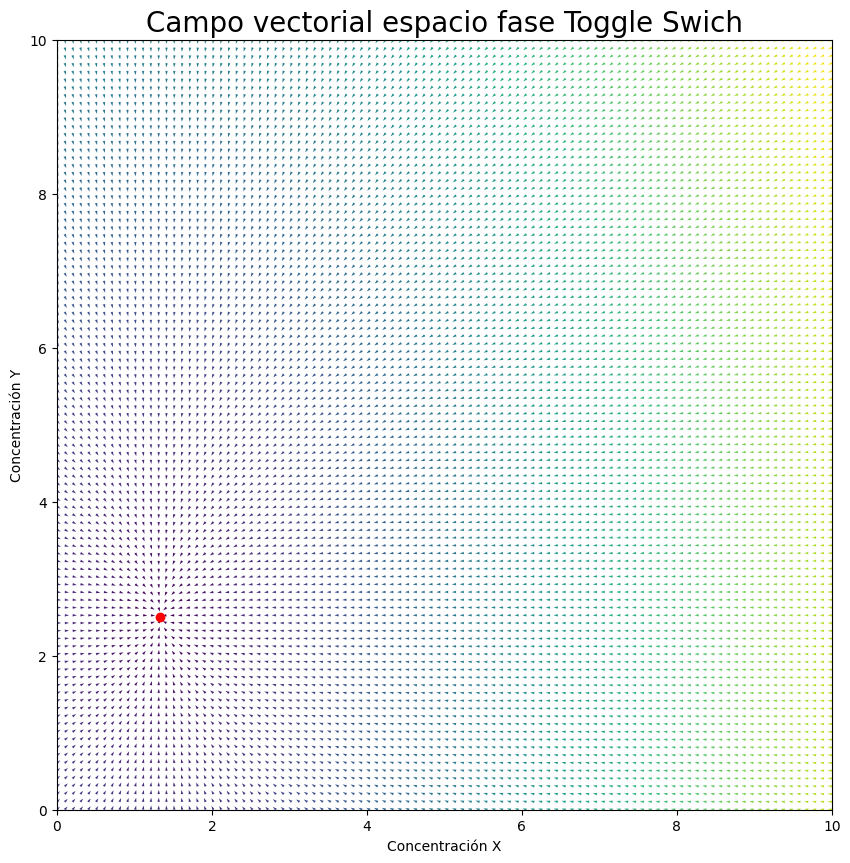

In [58]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 100)
y2 = np.linspace(0, 10, 100)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [59]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(1.295792982752759, 2.6098110807540595)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

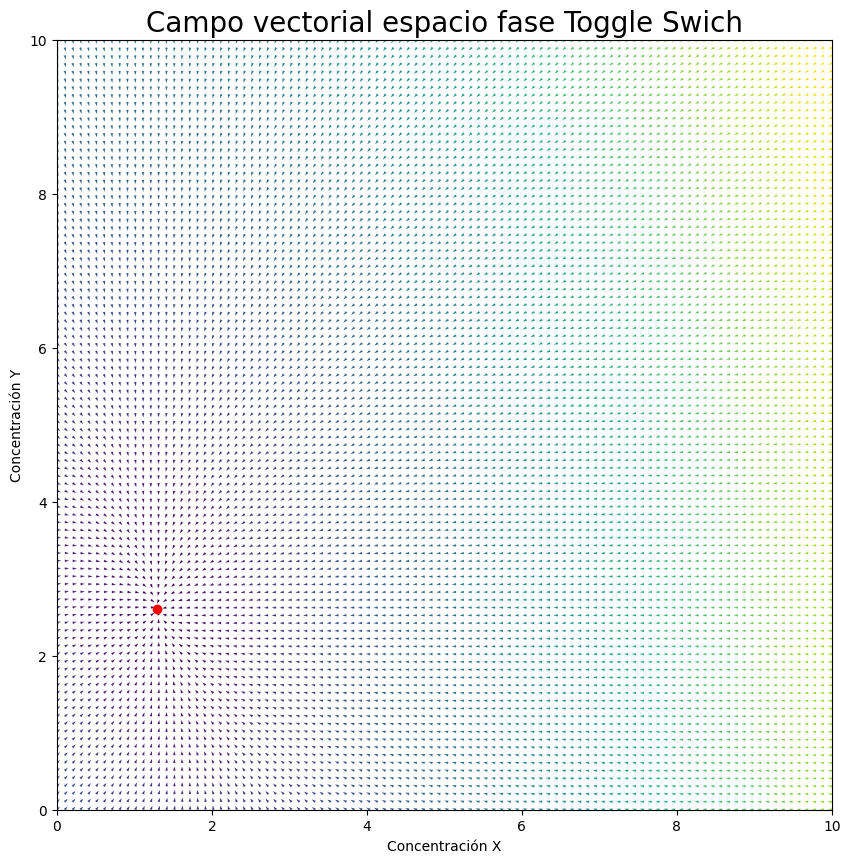

In [60]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 100)
y2pred = np.linspace(y_range_neg, y_range_pos, 100)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

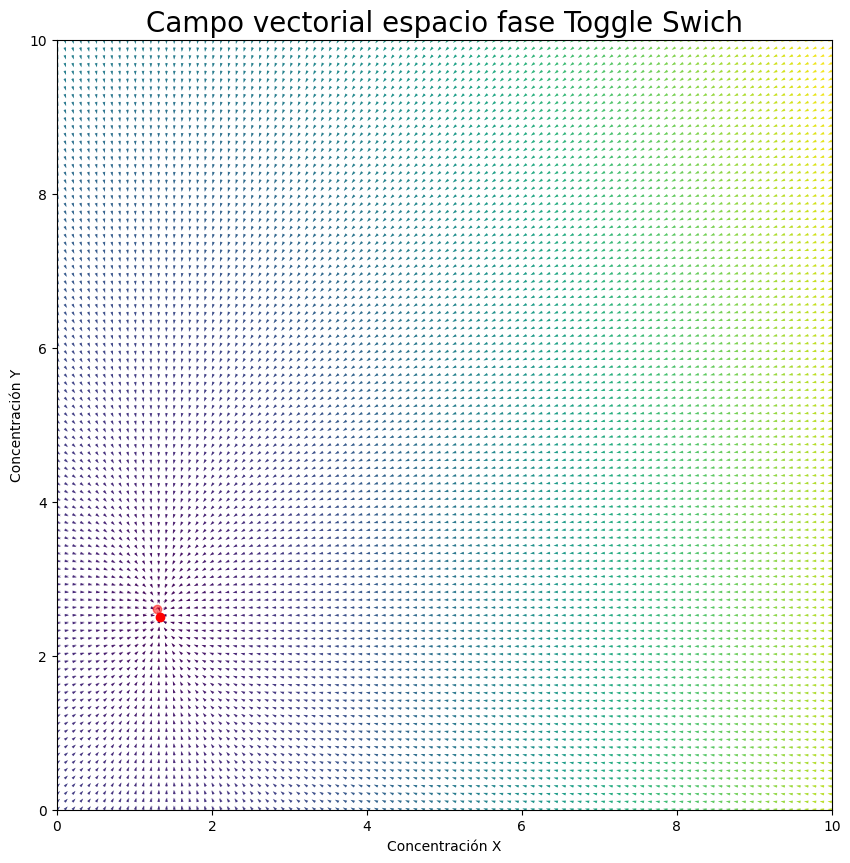

In [61]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

56.5537583650492


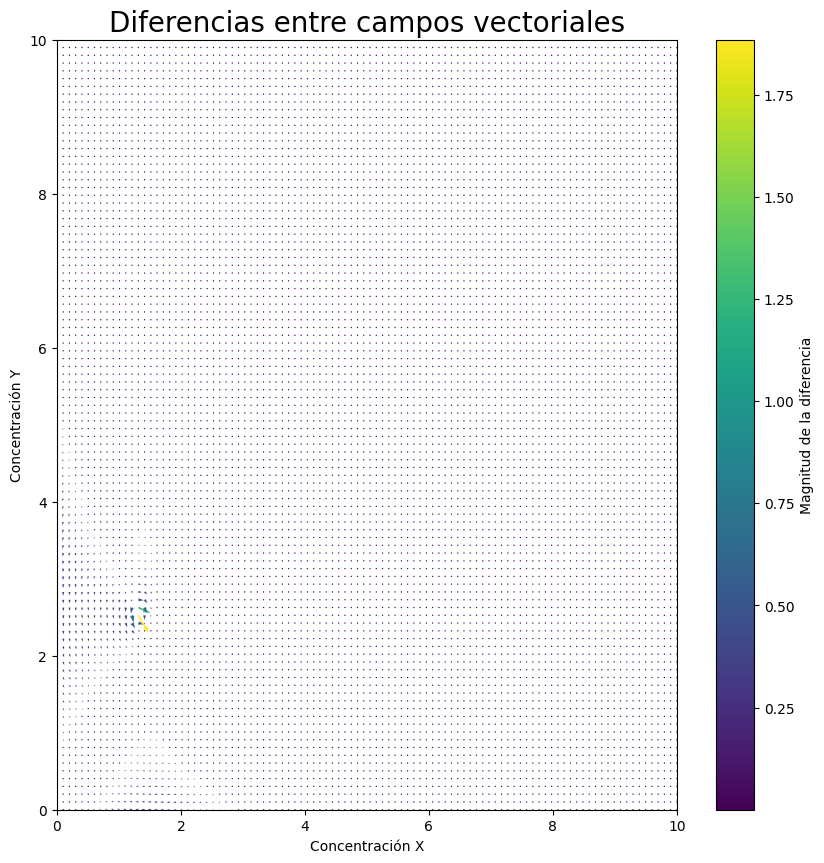

In [62]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

In [63]:
M_diff.mean()

0.037412242018427605

## Errores realativos

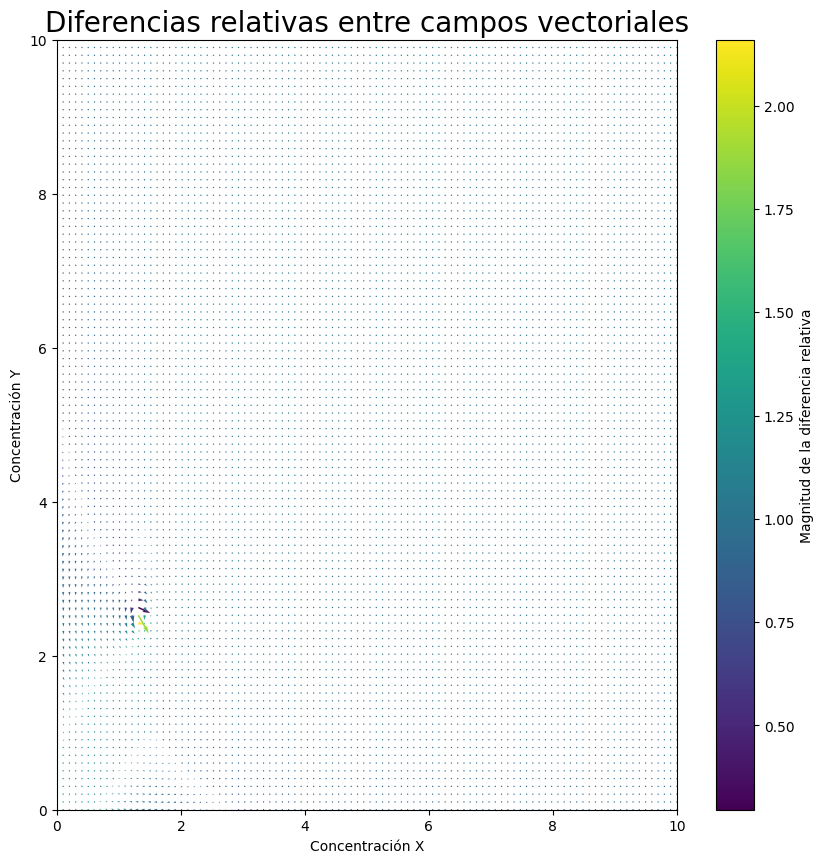

In [64]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [65]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 2.159606618179334
El valor de u1 en el error relativo máximo es: 0.18181818181818166
El valor de u1pred en el error relativo máximo es: -0.06596942880128687
El valor de v1 en el error relativo máximo es: 0.3787878787878789
El valor de v1pred en el error relativo máximo es: 0.9049887521503237


In [69]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 1.8851407311072117
El valor de u1 en el error relativo máximo es: 0.18181818181818166
El valor de u1pred en el error relativo máximo es: -0.11617608752279196
El valor de v1 en el error relativo máximo es: -0.1262626262626263
El valor de v1pred en el error relativo máximo es: 0.3999382470998185


In [68]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 12.57%


## Hacemos esto n veces

In [73]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 100)
    y2pred = np.linspace(y_range_neg, y_range_pos, 100)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 20ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 99.49%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 70.36%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 84.87%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 92.52%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 95.53%
--------------------------------------------
1/1 [=========================

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 99.95%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 95.69%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 98.04%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 100.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 99.40%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de 

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 85.55%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 94.86%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 99.73%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 99.27%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 82.76%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 99.74%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 95.04%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 95.21%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 95.34%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 81.89%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje

1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 91.18%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 93.40%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 86.29%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 97.19%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 99.94%
--------------------------------------------
1/1 [==============================] - 0s 21ms/step
El porcentaje

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 96.27%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 22.44%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 99.23%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 89.66%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 97.47%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

... (216 outputs left out)

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9856 es 100.00%
--------------------------------------------
1/1 [==============================] - 0s 19ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9857 es 99.66%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9858 es 99.04%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9859 es 98.98%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9860 es 98.91%
--------------------------------------------
1/1 [==============================] - 0s 18ms/step
El porc

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9900 es 97.99%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9901 es 21.56%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9902 es 94.93%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9903 es 91.43%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9904 es 99.10%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porce

--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9944 es 99.27%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9945 es 98.92%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9946 es 99.88%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9947 es 74.58%
--------------------------------------------
1/1 [==============================] - 0s 18ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9948 es 99.95%
--------------------------------------------
1/1 [==========

El promedio de los porcentajes es 90.48%


El promedio de los porcentajes es 90.48%


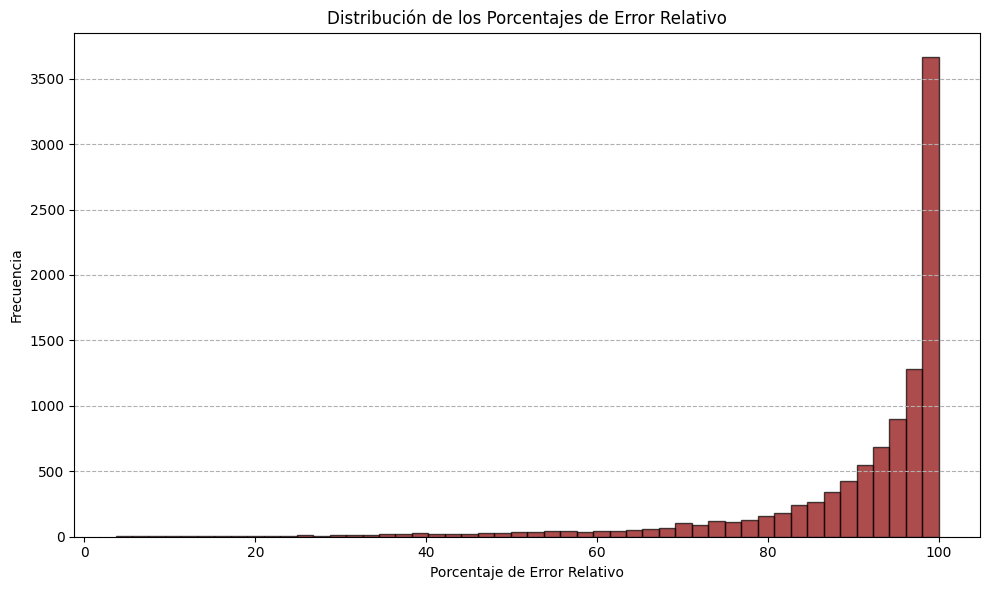

In [74]:
import matplotlib.pyplot as plt

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()